# 7. Real use (Objective O5)

The application logged every attempt by its real users, with the puzzle, the category and the outcome. Each model below replays
those attempts: it predicts each one before seeing the outcome and is then updated, so every prediction is a genuine forecast.

**Sources:** `eval/research/difficulty_model_evaluation.json` (`scripts/research/evaluate_difficulty_models.py`) and
`eval/research/mined_puzzles_summary.json`. The session files are private; only totals are published.

In [1]:
import pandas as pd
from nb_utils import ROOT, figures, load

pd.set_option('display.max_columns', None, 'display.width', 120)

logs = load('eval/research/difficulty_model_evaluation.json')
attempts = load('eval/research/mined_puzzles_summary.json')['attempts']
print(logs['events'], 'attempts by', logs['players'], 'players | solve rate', logs['solve_rate'], '| mined share', logs['mined_share'])

131 attempts by 5 players | solve rate 0.855 | mined share 0.695


In [2]:
pool_total = attempts['total'] - attempts['mined_total']
pool_solved = attempts['solved'] - attempts['mined_solved']
pd.DataFrame({'attempts': [attempts['mined_total'], pool_total],
              'solved': [attempts['mined_solved'], pool_solved],
              'solve rate': [attempts['mined_solved'] / attempts['mined_total'], pool_solved / pool_total]},
             index=['mined puzzles', 'Lichess puzzles']).round(3)

,attempts,solved,solve rate
mined puzzles,91,80,0.879
Lichess puzzles,40,32,0.800


In [3]:
table = pd.DataFrame(logs['models']).T[['log_loss', 'brier', 'auc', 'mean_prediction']].astype(float)
table.sort_values('log_loss').round(3)

,log_loss,brier,auc,mean_prediction
Base rate,0.434,0.132,0.543,0.775
"IRT, per category",0.586,0.198,0.543,0.707
Glicko-2 (symmetric),0.627,0.208,0.577,0.688
"IRT, θ only",0.635,0.215,0.487,0.704
Glicko-2 (pool frozen),0.698,0.237,0.456,0.685
"IRT, per category + PuzzleNet",0.747,0.244,0.522,0.651
Static Elo,1.266,0.392,0.528,0.434


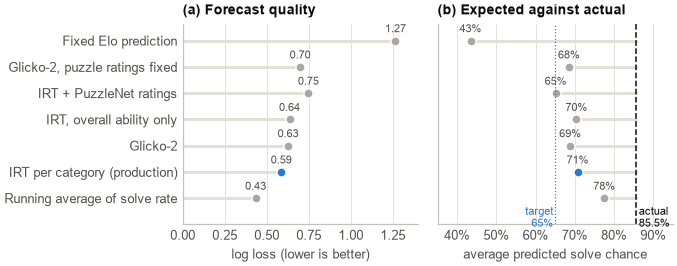

In [4]:
figures.real_use()

## Observations

- Players solved 85.5% of puzzles, well above the 65% target. Mined puzzles were solved more often (87.9%) than Lichess puzzles (80.0%).
- A fixed Elo prediction is by far the worst, expecting only 43% of puzzles to be solved.
- The production model with an offset per category is the best of the models that use difficulty (log loss 0.59).
- None of them beats a running average of the solve rate (0.43), because every model expected fewer solves than happened.
- Using PuzzleNet's ratings for mined puzzles makes forecasts worse (0.75), since it rates them almost 500 points too hard.
- **Limitation:** 131 attempts by five players are enough to see that predictions behave sensibly, but not to show that
  players improved. A controlled study is designed in `docs/USER_STUDY_PROTOCOL.md`.